# 01.1 — Manual Data Preparation: Hand-Labelled Bubble Periods

`01_data_preparation` derives bubble labels algorithmically (GSADF, LPPLS). This notebook takes the opposite approach: **hand-pick** the bubble episodes for each metal purely by eye, from the raw price series, as an independent, judgment-based label set.

This is useful as a sanity check — if GSADF/LPPLS episodes roughly line up with what a human analyst would circle on the chart, that's reassuring; where they diverge, it tells us something about the algorithmic methods' blind spots (see the GSADF-vs-LPPLS discussion in `02_model_training`).

### Process

1. Load the same raw price series used everywhere else in the project (`R/data_R/df_master.csv`).
2. Start from the user's rough date ranges (given verbally, one per visible "hump" in the chart).
3. Refine each boundary against the actual monthly price levels — pushing a boundary out where the price hadn't yet round-tripped back to its pre-spike baseline, or pulling it in where the rise/fall was too gradual to call a clear start/end. Each adjustment is noted below.
4. Build a binary daily flag per metal, plot it against the price series, and save it to `outputs/manual_bubble_labels.csv` in the same shape as `all_labels.csv` (so it can be dropped into the same evaluation pipeline as a 13th "variant" if desired).

### Refinements vs. the rough verbal description

| Metal | Rough description | Refinement made |
|---|---|---|
| Cobalt | 2017-end→2018-mid | Extended to end-Oct 2018 — price doesn't fully round-trip back to its ~27 pre-spike baseline until then |
| Cobalt | mid-2021→end-2022 | Extended ~1 month to end-Jan 2023 — Jan 2023 (22.3) is still near the 2022 highs; the real break comes in Feb 2023 (16.8) |
| Cobalt | 2 short spikes in 2025 | Dated to Mar–Apr 2025 and Oct 2025; the Oct one is still rising at the last available data point (2025-10-31), so it's right-censored (open-ended) |
| Copper | end-2022→1st-half-2023 | This is the weakest/most marginal "spike" of the set (3.47→4.12, only +19%) — kept per the user's instruction but flagged as low-confidence |
| Copper | beginning-2024→mid-2024 | Actual rise only starts in March, not January — narrowed accordingly |
| Copper | 2 short spikes in 2025 | Dated to Feb–Apr (mild) and Jun–Aug (the sharp tariff-driven COMEX/LME dislocation, +25% then crash) |
| Lithium | end-2021→beginning-2023 | Start pulled back to Sep 2021 (clear acceleration point) and end pushed to mid-Feb 2023 (Jan 2023 is still near the highs) |
| Nickel | 2022, then end-2022/beginning-2023 | Matches the rough description closely; boundaries set at the visible round-trip points (Jan–Jun 2022 for the LME squeeze, Oct 2022–Feb 2023 for the second hump) |


In [1]:
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt

os.makedirs('../outputs', exist_ok=True)

# ── Load raw price data (same source file as 01_data_preparation) ────────
df = pd.read_csv('../R/data_R/df_master.csv', sep=';', decimal=',', index_col=0)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

METALS = {
    'Cobalt':  'CODALY',
    'Copper':  'CUDALY',
    'Lithium': 'LIDALY',
    'Nickel':  'NIDALY',
}

print(f'Price data: {df["Date"].min().date()} → {df["Date"].max().date()}  ({len(df)} rows)')
print(f'Metals: {list(METALS.keys())}')


Price data: 2017-05-10 → 2025-10-31  (2152 rows)
Metals: ['Cobalt', 'Copper', 'Lithium', 'Nickel']


## Manual bubble windows

Each entry is an inclusive `[start, end]` date range, hand-picked by inspecting monthly-average prices against the rough verbal description (see refinement notes above).


In [2]:
# Right-censored windows (still rising as of the last data point, 2025-10-31) are marked with a trailing comment.
MANUAL_BUBBLES = {
    'Cobalt': [
        ('2017-11-15', '2018-10-31'),  # 2017-18 EV-battery run-up + round-trip back to baseline
        ('2021-01-15', '2021-03-31'),  # short Q1-2021 spike
        ('2021-07-01', '2023-01-31'),  # mid-2021 to Jan-2023 (crash starts Feb-2023)
        ('2025-03-01', '2025-04-30'),  # short spike #1
        ('2025-10-01', '2025-10-31'),  # short spike #2, right-censored
    ],
    'Copper': [
        ('2021-01-15', '2022-06-30'),  # 2021-22 post-COVID rally
        ('2022-10-01', '2023-04-30'),  # weak/marginal secondary hump
        ('2024-03-01', '2024-07-31'),  # 2024 COMEX short-squeeze rally
        ('2025-02-01', '2025-04-15'),  # short spike #1 (mild)
        ('2025-06-01', '2025-08-15'),  # short spike #2 (tariff-driven COMEX/LME dislocation)
    ],
    'Lithium': [
        ('2021-09-01', '2023-02-15'),  # the big EV-demand mega-bubble
        ('2023-05-01', '2023-07-31'),  # shorter secondary bounce
    ],
    'Nickel': [
        ('2022-01-15', '2022-06-15'),  # March-2022 LME short-squeeze
        ('2022-10-15', '2023-02-15'),  # end-2022 / early-2023 second hump
    ],
}

labels = df[['Date']].copy()
for metal, windows in MANUAL_BUBBLES.items():
    flag = np.zeros(len(df), dtype=int)
    for start, end in windows:
        mask = (df['Date'] >= start) & (df['Date'] <= end)
        flag[mask.values] = 1
    labels[f'{metal}_manual'] = flag

print(f'{"Metal":10s}  {"Days":>5s}  {"Prev%":>6s}  {"Episodes":>8s}')
print('-' * 36)
for metal in METALS:
    arr = labels[f'{metal}_manual'].values
    n_ep = len(MANUAL_BUBBLES[metal])
    print(f'{metal:10s}  {int(arr.sum()):5d}  {100*arr.mean():5.1f}%  {n_ep:8d}')


Metal        Days   Prev%  Episodes
------------------------------------
Cobalt        765   35.5%         5
Copper        745   34.6%         5
Lithium       446   20.7%         2
Nickel        195    9.1%         2


## Plot: price series with manual bubble periods shaded


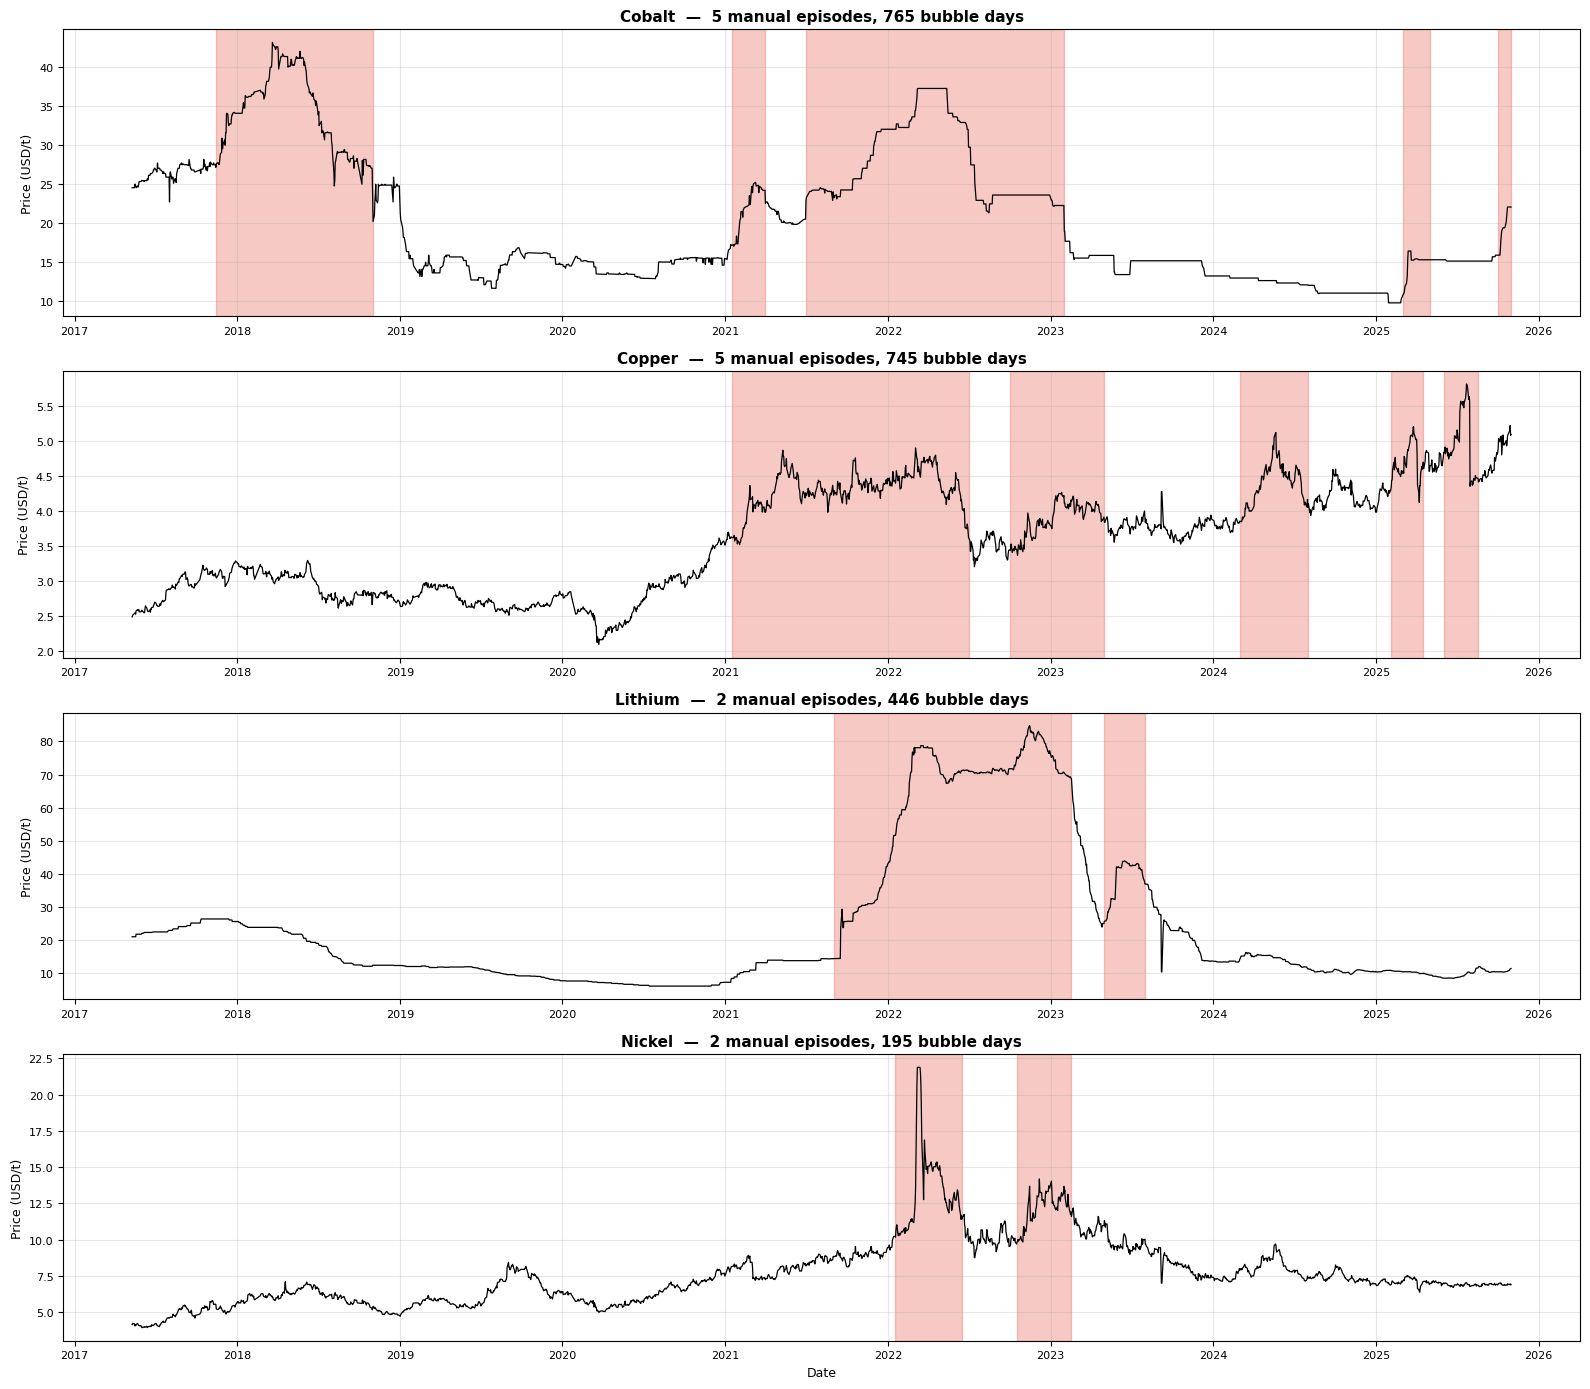

Saved → ../outputs/01.1_manual_bubbles.png


In [3]:
fig, axes = plt.subplots(4, 1, figsize=(16, 14), sharex=False)

for ax, (metal, col) in zip(axes, METALS.items()):
    ax.plot(df['Date'], df[col], color='black', lw=0.9)

    arr = labels[f'{metal}_manual'].values
    in_b = False
    for i in range(len(arr)):
        if arr[i] == 1 and not in_b:
            s = df['Date'].iloc[i]; in_b = True
        elif (arr[i] == 0 or i == len(arr) - 1) and in_b:
            ax.axvspan(s, df['Date'].iloc[i], color='#e74c3c', alpha=0.30)
            in_b = False

    n_days = int(arr.sum())
    n_ep   = len(MANUAL_BUBBLES[metal])
    ax.set_title(f'{metal}  —  {n_ep} manual episodes, {n_days} bubble days',
                 fontsize=11, fontweight='bold')
    ax.set_ylabel('Price (USD/t)', fontsize=9)
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel('Date', fontsize=9)
plt.tight_layout()

out_path = '../outputs/01.1_manual_bubbles.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print(f'Saved → {out_path}')


## Save manual labels

Saved in the same row layout as `all_labels.csv` — Date + the 4 price columns + one binary column per metal (`{Metal}_manual`) — so it can be merged into the model-training pipeline as an extra label variant if desired.


In [4]:
price_cols = list(METALS.values())
output = df[['Date'] + price_cols].copy()
for metal in METALS:
    output[f'{metal}_manual'] = labels[f'{metal}_manual'].values

out_path = '../outputs/manual_bubble_labels.csv'
output.to_csv(out_path, index=False)
print(f'Saved → {out_path}  ({os.path.getsize(out_path)/1024:.1f} KB)')
print(f'Columns: {len(output.columns)}  Rows: {len(output)}')


Saved → ../outputs/manual_bubble_labels.csv  (99.7 KB)
Columns: 9  Rows: 2152


## Model training on the manual labels

Same architecture as `02_model_training`: the 48 lagged observed-market features (returns, 10-day volatility, relative level for the 4 metal prices + 12 market/macro series), a 5-fold expanding-window `TimeSeriesSplit`, and a decision threshold chosen on the training fold only. The only difference is there's a single hand-picked label per metal instead of 12 algorithmic variants, so this is 4 metals × 5 models = 20 experiments rather than 240.


In [7]:
import time, warnings
warnings.filterwarnings('ignore')
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, confusion_matrix, precision_recall_curve,
                              average_precision_score, f1_score)
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

SEED = 42
LEVEL_NORM_WINDOW = 250
METAL_NAMES = list(METALS.keys())

# GSADF flag columns aren't predictors here — drop them, keep only the manual target
BD_COLS = [c for c in df.columns if c.endswith('_BD')]
df_ml_input = df.drop(columns=BD_COLS).copy()
for metal in METALS:
    df_ml_input[f'{metal}_manual'] = labels[f'{metal}_manual'].values


def prepare_features(target_metal, df_master):
    """Same 48 lagged features as 02_model_training (see that notebook for the full rationale)."""
    target_col = f'{target_metal}_manual'
    price_cols = list(METALS.values())
    macro_cols = [c for c in df_master.columns
                  if c not in ['Date'] + price_cols
                  and not any(c.startswith(m + '_') for m in METAL_NAMES)]
    out = pd.DataFrame({'Date': df_master['Date']})
    for col in price_cols + macro_cols:
        s = df_master[col]
        if (s <= 0).any():                       # e.g. OIL_WTI went negative in Apr-2020
            ret = s.diff()
            rel = s - s.rolling(LEVEL_NORM_WINDOW, min_periods=60).mean()
        else:
            ret  = np.log(s).diff()
            roll = s.rolling(LEVEL_NORM_WINDOW, min_periods=60).mean()
            rel  = np.log(s / roll)
        out[col + '_Ret_L1']      = ret.shift(1)
        out[col + '_Vol10_L1']    = ret.rolling(10).std().shift(1)
        out[col + '_RelLevel_L1'] = rel.shift(1)
    out['Target'] = df_master[target_col].astype(int)
    return out.dropna().reset_index(drop=True)


def find_f1_threshold(y_true, y_prob):
    pre, rec, thr = precision_recall_curve(y_true, y_prob)
    with np.errstate(invalid='ignore'):
        f1s = np.where((pre[:-1] + rec[:-1]) > 0,
                       2 * pre[:-1] * rec[:-1] / (pre[:-1] + rec[:-1]), 0.0)
    return float(thr[int(np.argmax(f1s))]), float(f1s.max())


def pick_threshold(Xtr, ytr, model_fn, needs_scale, inner_frac=0.25):
    """Threshold chosen on the training fold only (inner val split, or a prevalence-matched fallback)."""
    n_in = int(len(Xtr) * (1 - inner_frac))
    Xi, Xv, yi, yv = Xtr[:n_in], Xtr[n_in:], ytr[:n_in], ytr[n_in:]
    if yi.sum() >= 3 and yv.sum() >= 1 and len(np.unique(yv)) > 1:
        if needs_scale:
            sc = StandardScaler(); Xi = sc.fit_transform(Xi); Xv = sc.transform(Xv)
        m = model_fn(); m.fit(Xi, yi)
        thr, _ = find_f1_threshold(yv, m.predict_proba(Xv)[:, 1])
        return thr
    X_ = Xtr
    if needs_scale:
        sc = StandardScaler(); X_ = sc.fit_transform(X_)
    m = model_fn(); m.fit(X_, ytr)
    prev = float(ytr.mean())
    return float(np.quantile(m.predict_proba(X_)[:, 1], 1 - prev))


def label_episodes(y):
    eps = np.zeros(len(y), dtype=int); eid = 0; in_b = False
    for i in range(len(y)):
        if y[i] == 1 and not in_b:
            eid += 1; in_b = True
        elif y[i] == 0:
            in_b = False
        if y[i] == 1:
            eps[i] = eid
    return eps


DEFAULT_PARAMS = {
    'LASSO':    dict(penalty='l1', solver='saga', C=0.1, max_iter=10000),
    'RF':       dict(n_estimators=300, max_depth=10, min_samples_leaf=3, max_features='sqrt'),
    'XGBoost':  dict(max_depth=3, learning_rate=0.05, n_estimators=300, min_child_weight=2,
                     reg_alpha=0.5, reg_lambda=2.0, subsample=0.8, colsample_bytree=0.8),
    'LightGBM': dict(max_depth=3, learning_rate=0.05, n_estimators=300, min_child_samples=5,
                     reg_alpha=0.5, reg_lambda=2.0, subsample=0.8, colsample_bytree=0.8),
    'CatBoost': dict(depth=3, learning_rate=0.05, iterations=300, l2_leaf_reg=3.0, subsample=0.8),
}


def build_model(mname):
    """Same fixed hyperparameters as 02_model_training's DEFAULT_PARAMS — no per-model tuning here."""
    p = dict(DEFAULT_PARAMS[mname])
    if mname == 'LASSO':    return LogisticRegression(random_state=SEED, **p)
    if mname == 'LightGBM': return lgb.LGBMClassifier(**p, verbose=-1, random_state=SEED)
    if mname == 'XGBoost':  return xgb.XGBClassifier(**p, eval_metric='auc', verbosity=0, random_state=SEED)
    if mname == 'RF':       return RandomForestClassifier(**p, random_state=SEED)
    if mname == 'CatBoost': return CatBoostClassifier(**p, verbose=0, random_state=SEED)
    raise ValueError(mname)


print('Helpers ready (same feature set / model configs as 02_model_training).')


Helpers ready (same feature set / model configs as 02_model_training).


In [8]:
MODEL_NAMES       = ['LASSO', 'RF', 'XGBoost', 'LightGBM', 'CatBoost']
NEEDS_SCALE       = {'LASSO'}
N_SPLITS          = 5
MIN_TEST_EPISODES = 3

results = []
t0 = time.time()

for metal in METALS:
    df_feat = prepare_features(metal, df_ml_input)
    feats = [c for c in df_feat.columns if c not in ['Date', 'Target']]
    X = df_feat[feats].values
    y = df_feat['Target'].values

    for mname in MODEL_NAMES:
        needs_scale = mname in NEEDS_SCALE
        model_fn = lambda n=mname: build_model(n)
        folds, fold_metrics = [], []

        for train_idx, test_idx in TimeSeriesSplit(n_splits=N_SPLITS).split(X):
            Xtr, Xte = X[train_idx], X[test_idx]
            ytr, yte = y[train_idx], y[test_idx]
            if ytr.sum() < 5 or yte.sum() == 0 or len(np.unique(yte)) < 2:
                continue

            thr = pick_threshold(Xtr, ytr, model_fn, needs_scale)
            if needs_scale:
                sc = StandardScaler(); Xtr = sc.fit_transform(Xtr); Xte = sc.transform(Xte)

            m = model_fn(); m.fit(Xtr, ytr)
            p = m.predict_proba(Xte)[:, 1]
            pred = (p >= thr).astype(int)
            folds.append((yte, p, thr))

            tn, fp, fn, tp = confusion_matrix(yte, pred, labels=[0, 1]).ravel()
            fold_metrics.append(dict(
                auc=roc_auc_score(yte, p), ap=average_precision_score(yte, p),
                f1=f1_score(yte, pred, zero_division=0),
                sens=tp / (tp + fn) if (tp + fn) > 0 else 0.0,
                prec=tp / (tp + fp) if (tp + fp) > 0 else 0.0))

        if not folds:
            results.append(dict(Metal=metal, Model=mname, Folds=0, TestEps=0,
                                 AUC=np.nan, AP=np.nan, F1=np.nan, Sens=np.nan, Prec=np.nan, EpDet='0/0'))
            continue

        fm = pd.DataFrame(fold_metrics)
        ep_total = ep_det = 0
        for yte_f, p_f, thr_f in folds:
            eps = label_episodes(yte_f)
            pred_f = (p_f >= thr_f).astype(int)
            for eid in set(eps[eps > 0]):
                ep_total += 1
                if pred_f[eps == eid].sum() > 0:
                    ep_det += 1

        results.append(dict(
            Metal=metal, Model=mname, Folds=len(folds), TestEps=ep_total,
            AUC=round(float(fm.auc.mean()), 3), AP=round(float(fm.ap.mean()), 3),
            F1=round(float(fm.f1.mean()), 3), Sens=round(float(fm.sens.mean()), 3),
            Prec=round(float(fm.prec.mean()), 3), EpDet=f'{ep_det}/{ep_total}'))

df_results_manual = pd.DataFrame(results)
df_results_manual.to_csv('../outputs/manual_results.csv', index=False)
print(f'Done — {len(df_results_manual)} experiments in {time.time()-t0:.0f}s')
print('Saved → outputs/manual_results.csv')


Done — 20 experiments in 135s
Saved → outputs/manual_results.csv


## Results (manual labels)

Fold-averaged metrics, one row per metal × model. `EpDet` = bubble episodes detected / total test episodes.


Lithium and Nickel only have 2 hand-picked episodes each, both clustered within a single ~1-year window (2021-23 and 2022-23 respectively). That's below the 3-test-episode reportability bar used everywhere else in this project — and for Nickel specifically, the two episodes sit close enough together that no expanding-window fold ever has positives on both sides of the train/test split, so every fold gets skipped (`Folds=0`). Shown below anyway, clearly marked, rather than silently dropped.

In [11]:
df_valid = df_results_manual[df_results_manual.Folds > 0].copy()
df_valid['Reportable'] = df_valid.TestEps >= MIN_TEST_EPISODES
df_ok_manual = df_valid[df_valid.Reportable].copy()

print(df_valid.sort_values(['Metal', 'AP'], ascending=[True, False])
      .set_index(['Metal', 'Model'])[['Folds', 'TestEps', 'Reportable', 'AUC', 'AP', 'F1', 'Sens', 'Prec', 'EpDet']]
      .to_string())

no_folds = sorted(set(METALS) - set(df_valid.Metal.unique()))
if no_folds:
    print(f'\nNo valid CV fold at all for: {no_folds} — see note above.')


                  Folds  TestEps  Reportable    AUC     AP     F1   Sens   Prec EpDet
Metal   Model                                                                        
Cobalt  RF            3        5        True  0.859  0.720  0.488  0.512  0.540   3/5
        LightGBM      3        5        True  0.834  0.702  0.513  0.535  0.531   3/5
        LASSO         3        5        True  0.825  0.688  0.471  0.477  0.589   4/5
        XGBoost       3        5        True  0.829  0.685  0.503  0.530  0.540   3/5
        CatBoost      3        5        True  0.814  0.668  0.560  0.621  0.529   3/5
Copper  RF            3        7        True  0.485  0.602  0.595  0.875  0.512   7/7
        LASSO         3        7        True  0.588  0.586  0.598  0.875  0.514   6/7
        XGBoost       3        7        True  0.445  0.552  0.623  0.927  0.508   7/7
        LightGBM      3        7        True  0.422  0.547  0.603  0.891  0.508   7/7
        CatBoost      3        7        True  0.453  0

## Comparison: manual vs. algorithmic labels

For each metal: the best-performing model on the manual label, vs. the best-performing (model, variant) among the reportable GSADF and LPPLS experiments from `02_model_training` (`outputs/all_results.csv`). Ranked by average precision (AP), since bubbles are rare and AP is more informative than AUC at low prevalence. Nickel has no row on the manual side — see the reportability note above.


In [13]:
algo = pd.read_csv('../outputs/all_results.csv')
algo_ok = algo[algo.Note.isna() & algo.AUC.notna()].copy()
algo_ok['Method'] = np.where(algo_ok.Variant.str.startswith('gsadf'), 'GSADF', 'LPPLS')

rows = []
for metal in METALS:
    manual_sub = df_valid[df_valid.Metal == metal].sort_values('AP', ascending=False)
    if len(manual_sub) == 0:
        rows.append(dict(Metal=metal, Manual_Model='— (no valid fold)', Manual_AUC=np.nan, Manual_AP=np.nan,
                          GSADF_Variant='—', GSADF_AUC=np.nan, GSADF_AP=np.nan,
                          LPPLS_Variant='—', LPPLS_AUC=np.nan, LPPLS_AP=np.nan))
        continue
    best_manual = manual_sub.iloc[0]
    sub = algo_ok[algo_ok.Metal == metal]
    best_gsadf = sub[sub.Method == 'GSADF'].sort_values('AP', ascending=False)
    best_lppls = sub[sub.Method == 'LPPLS'].sort_values('AP', ascending=False)
    rows.append(dict(
        Metal=metal,
        Manual_Model=best_manual.Model, Manual_AUC=best_manual.AUC, Manual_AP=best_manual.AP,
        GSADF_Variant=best_gsadf.iloc[0].Variant if len(best_gsadf) else '—',
        GSADF_AUC=best_gsadf.iloc[0].AUC if len(best_gsadf) else np.nan,
        GSADF_AP=best_gsadf.iloc[0].AP if len(best_gsadf) else np.nan,
        LPPLS_Variant=best_lppls.iloc[0].Variant if len(best_lppls) else '—',
        LPPLS_AUC=best_lppls.iloc[0].AUC if len(best_lppls) else np.nan,
        LPPLS_AP=best_lppls.iloc[0].AP if len(best_lppls) else np.nan,
    ))

comparison = pd.DataFrame(rows)
comparison.to_csv('../outputs/method_comparison.csv', index=False)
print(comparison.to_string(index=False))
print('\nSaved → outputs/method_comparison.csv')


  Metal      Manual_Model  Manual_AUC  Manual_AP GSADF_Variant  GSADF_AUC  GSADF_AP     LPPLS_Variant  LPPLS_AUC  LPPLS_AP
 Cobalt                RF       0.859      0.720     gsadf_ols      0.762     0.671        lppls_0.01      0.920     0.492
 Copper                RF       0.485      0.602             —        NaN       NaN lppls_0.01_period      0.635     0.316
Lithium          CatBoost       0.892      0.816     gsadf_ols      0.738     0.617 lppls_0.01_period      0.709     0.319
 Nickel — (no valid fold)         NaN        NaN             —        NaN       NaN                 —        NaN       NaN

Saved → outputs/method_comparison.csv


### Reading this table with the right caveat

The manual label scores higher than both algorithmic methods on every metal shown — but that's not a fair "the hand-picked label is better" conclusion on its own. The manual episodes were drawn by eye with full hindsight of the whole price chart, are far more prevalent (21–35% of days vs. typically 5–15% for GSADF/LPPLS), and cover long, obviously-trending windows — all of which make a day easier to classify from `_RelLevel_L1`/`_Vol10_L1` alone, regardless of whether "bubble" is the right word for it. The useful takeaway isn't the score gap, it's the *shape* of agreement: where a metal's best algorithmic AP is already close to the manual AP (Cobalt), GSADF is tracking what a human would circle reasonably well; where the gap is largest (Copper has no reportable GSADF combo at all, Lithium's LPPLS AP is a third of the manual one), that's the same blind spot already flagged in `02_model_training` — GSADF undercounts smaller/shorter episodes, LPPLS is noisier on the very large ones.
